# Graph-based Knowledge Tracing (GKT) - Kaggle GPU Runner

Notebook huấn luyện và đánh giá mô hình **Graph-based Knowledge Tracing (GKT)** (Nakagawa et al., WI 2019) so sánh với baseline **Deep Knowledge Tracing (DKT)** (Piech et al., NeurIPS 2015) trên tập dữ liệu ASSISTments.

### Các cấu trúc đồ thị được khảo sát:
1. **DKT Baseline**: Mô hình tuần tự không sử dụng đồ thị.
2. **GKT - Dense**: Đồ thị đầy đủ, trọng số đồng đều $1 / (N - 1)$.
3. **GKT - Transition**: Đồ thị chuyển tiếp xác suất (xây dựng nghiêm ngặt từ tập train chống rò rỉ dữ liệu).
4. **GKT - Identity (Ablation)**: Ma trận kề đơn vị $I$ (chỉ giữ self-loop, không liên kết giữa các KC).
5. **GKT - Zero (Ablation)**: Ma trận kề bằng $0$ (cô lập hoàn toàn các khái niệm).
6. **GKT - PAM**: Ma trận kề tham số tự học (Parameter Adjacency Matrix).
7. **GKT - MHA**: Khởi tạo đồ thị động bằng Multi-Head Attention.
8. **GKT - VAE**: Suy diễn cạnh đồ thị ẩn qua Variational Autoencoder với Gumbel-Softmax.


## 0. Thiết lập môi trường & Clone Repository


In [1]:
import os
import sys
import shutil
import subprocess
from pathlib import Path

# Tự động phát hiện môi trường Kaggle vs Local
IS_KAGGLE = Path('/kaggle/working').exists()
REPO_URL = "https://github.com/linhnnh688/Knowledge-Tracing.git"

if IS_KAGGLE:
    REPO_DIR = Path('/kaggle/working/Knowledge-Tracing')
    if not (REPO_DIR / '.git').exists():
        if REPO_DIR.exists():
            shutil.rmtree(REPO_DIR, ignore_errors=True)
        print("Cloning Knowledge-Tracing repository...")
        subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)])
    else:
        print("Syncing repository with latest origin/main...")
        try:
            # Đồng bộ triệt để với origin/main (tránh lỗi diverging branches hoặc conflict)
            subprocess.check_call(["git", "-C", str(REPO_DIR), "fetch", "origin", "main", "--depth", "1"])
            subprocess.check_call(["git", "-C", str(REPO_DIR), "reset", "--hard", "origin/main"])
        except Exception as e:
            print(f"Git sync error ({e}), re-cloning fresh repository...")
            shutil.rmtree(REPO_DIR, ignore_errors=True)
            subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)])
    GKT_DIR = REPO_DIR / 'GKT'
else:
    REPO_DIR = Path.cwd() if (Path.cwd() / "GKT").exists() else Path.cwd().parent
    GKT_DIR = REPO_DIR / "GKT"

os.chdir(GKT_DIR)
if str(GKT_DIR) not in sys.path:
    sys.path.insert(0, str(GKT_DIR))

print(f"Working Directory: {Path.cwd()}")


Cloning Knowledge-Tracing repository...


Cloning into '/kaggle/working/Knowledge-Tracing'...


Working Directory: /kaggle/working/Knowledge-Tracing/GKT


In [2]:
# Trên Kaggle GPU, PyTorch với CUDA đã được cài đặt sẵn.
# Chỉ cài đặt thêm nếu thiếu, tuyệt đối không cài đè torch để tránh mất hỗ trợ CUDA.
%pip install -q pandas scipy scikit-learn matplotlib tqdm


Note: you may need to restart the kernel to use updated packages.


In [3]:
import random
import time
import gc
import datetime
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.autograd import Variable
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from models import GKT, MultiHeadAttention, VAE, DKT
from metrics import KTLoss, VAELoss
from processing import load_dataset

# Đảm bảo DKT.forward luôn chuyển feature_lens sang CPU (khắc phục lỗi PyTorch GPU pack_padded_sequence)
def _safe_dkt_forward(self, features, questions):
    feat_one_hot = torch.eye(self.feature_dim, device=features.device)
    feat_one_hot = torch.cat((feat_one_hot, torch.zeros(1, self.feature_dim, device=features.device)), dim=0)
    feat = torch.where(features != -1, features, self.feature_dim * torch.ones_like(features, device=features.device))
    features_emb = F.embedding(feat, feat_one_hot)

    # PyTorch pack_padded_sequence yêu cầu lengths phải là 1D CPU tensor
    feature_lens = torch.ne(questions, -1).sum(dim=1).cpu()
    feature_lens = torch.clamp(feature_lens, min=1)
    x_packed = pack_padded_sequence(features_emb, feature_lens, batch_first=True, enforce_sorted=False)
    output_packed, _ = self.rnn(x_packed)
    output_padded, _ = pad_packed_sequence(output_packed, batch_first=True, total_length=features.shape[1])
    yt = self.f_out(output_padded)
    yt = torch.sigmoid(yt)
    yt = yt[:, :-1, :]
    pred_res = self._get_next_pred(yt, questions)
    return pred_res

DKT.forward = _safe_dkt_forward

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"Device Count: {torch.cuda.device_count()}")


PyTorch Version: 2.11.0+cu128
CUDA Available: True
GPU Device: Tesla T4
Device Count: 2


## 1. Cấu hình thực nghiệm (Experiment Configuration)

> [!TIP]
> - Đặt `QUICK_RUN = True` để chạy thử nghiệm nhanh trên `assistment_test15.csv` (~1-2 phút).
> - Đặt `QUICK_RUN = False` để chạy toàn bộ tập dữ liệu ASSISTments 2009 (`skill_builder_data.csv`).


In [4]:
# Cấu hình thực nghiệm
QUICK_RUN = True  # Đổi thành False để chạy toàn bộ dataset ASSISTments 2009

DATA_DIR = Path.cwd() / 'data'
DATA_FILE = 'assistment_test15.csv' if QUICK_RUN else 'skill_builder_data.csv'
EPOCHS = 10 if QUICK_RUN else 20
BATCH_SIZE = 128
LR = 0.001
HID_DIM = 32
EMB_DIM = 32
ATTN_DIM = 32
EDGE_TYPES = 2

OUTPUT_DIR = Path('/kaggle/working/gkt_outputs') if IS_KAGGLE else (Path.cwd() / 'outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Config: data={DATA_FILE}, epochs={EPOCHS}, batch_size={BATCH_SIZE}, quick_run={QUICK_RUN}")
print(f"Outputs will be saved to: {OUTPUT_DIR}")


Config: data=assistment_test15.csv, epochs=10, batch_size=128, quick_run=True
Outputs will be saved to: /kaggle/working/gkt_outputs


## 2. Khám phá dữ liệu (Exploratory Data Analysis)


In [5]:
df_small = pd.read_csv(DATA_DIR / 'assistment_test15.csv')
df_full = pd.read_csv(DATA_DIR / 'skill_builder_data.csv', low_memory=False)

print("=== assistment_test15.csv (Tập nhỏ kiểm thử) ===")
print(f"Shape: {df_small.shape}")
print(f"Số học sinh (users): {df_small['user_id'].nunique()}")
print(f"Số kỹ năng (skills): {df_small['skill_id'].nunique()}")
print(f"Tỷ lệ trả lời đúng: {df_small['correct'].mean():.3%}")

print("\n=== skill_builder_data.csv (Tập đầy đủ ASSISTments 2009) ===")
print(f"Shape: {df_full.shape}")
print(f"Số học sinh (users): {df_full['user_id'].nunique()}")
print(f"Số kỹ năng (skills): {df_full['skill_id'].nunique()}")
print(f"Tỷ lệ trả lời đúng: {df_full['correct'].mean():.3%}")


=== assistment_test15.csv (Tập nhỏ kiểm thử) ===
Shape: (1887, 30)
Số học sinh (users): 15
Số kỹ năng (skills): 74
Tỷ lệ trả lời đúng: 65.236%

=== skill_builder_data.csv (Tập đầy đủ ASSISTments 2009) ===
Shape: (525534, 30)
Số học sinh (users): 4217
Số kỹ năng (skills): 123
Tỷ lệ trả lời đúng: 67.947%


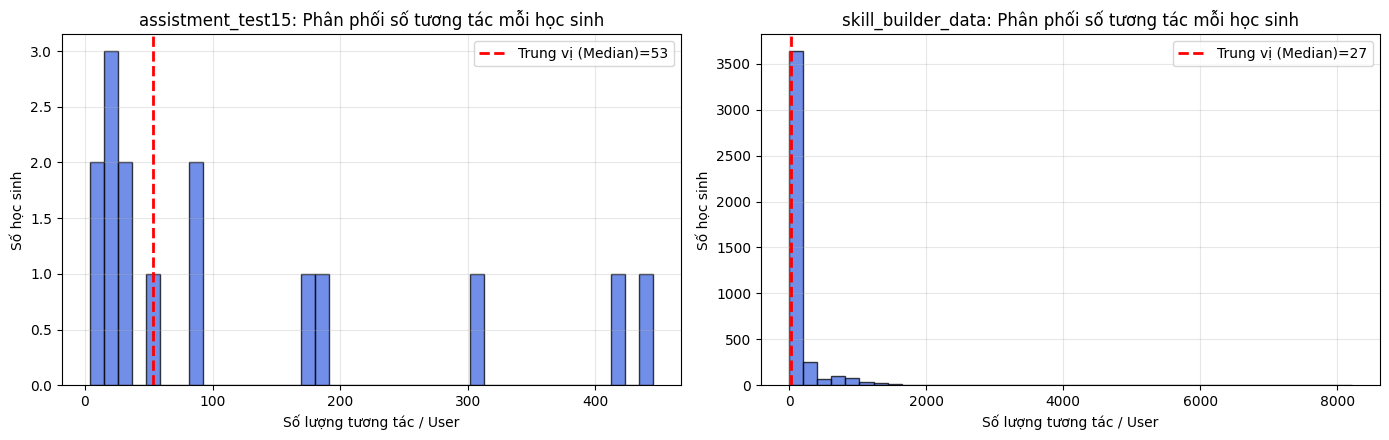

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, df) in zip(axes, [('assistment_test15', df_small), ('skill_builder_data', df_full)]):
    user_counts = df.groupby('user_id').size()
    ax.hist(user_counts, bins=40, edgecolor='black', alpha=0.75, color='royalblue')
    ax.set_title(f"{name}: Phân phối số tương tác mỗi học sinh")
    ax.set_xlabel('Số lượng tương tác / User')
    ax.set_ylabel('Số học sinh')
    median_val = user_counts.median()
    ax.axvline(median_val, color='red', linestyle='--', linewidth=2, label=f'Trung vị (Median)={median_val:.0f}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_sequence_distribution.png', dpi=150)
plt.show()


## 3. Hàm huấn luyện & đánh giá chuẩn hóa (`run_experiment`)

Được tối ưu để:
- Chạy trơn tru trên cả **GPU (CUDA)** và **CPU**.
- Tránh rò rỉ dữ liệu bằng cách phân chia train/val/test theo người học và truyền `seed` đồng nhất.
- Truyền `binary=True` khớp với `res_len=2` giúp tiết kiệm bộ nhớ GPU tối đa.
- Forward pass một lần duy nhất cho GKT-VAE (tránh tính toán lặp lại và đồng bộ hóa mẫu đồ thị ẩn).
- Checkpoint mô hình tối ưu theo `val_loss` và khôi phục trọng số tốt nhất trước khi đánh giá test.


In [7]:
def run_experiment(
    data_file,
    model_type='GKT',
    graph_type='Dense',
    epochs=20,
    batch_size=128,
    lr=0.001,
    hid_dim=32,
    emb_dim=32,
    attn_dim=32,
    edge_types=2,
    dropout=0.0,
    train_ratio=0.6,
    val_ratio=0.2,
    seed=42,
    device=None
):
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    is_cuda = (device.type == 'cuda')

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if is_cuda:
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

    data_path = str(DATA_DIR / data_file)

    # Nạp dữ liệu với seed đồng nhất chống rò rỉ dữ liệu
    concept_num, graph, train_loader, valid_loader, test_loader = load_dataset(
        data_path, batch_size, graph_type,
        train_ratio=train_ratio, val_ratio=val_ratio,
        shuffle=True, model_type=model_type, use_cuda=is_cuda,
        seed=seed
    )

    res_len = 2
    graph_model = None

    if model_type == 'GKT':
        if graph_type == 'MHA':
            graph_model = MultiHeadAttention(edge_types, concept_num, emb_dim, attn_dim, dropout=dropout)
        elif graph_type == 'VAE':
            graph_model = VAE(emb_dim, 32, edge_types, 32, 32, concept_num,
                             edge_type_num=edge_types, tau=0.5, factor=True, dropout=dropout, bias=True)
        if is_cuda and graph_type in ['MHA', 'VAE']:
            graph_model = graph_model.to(device)
            
        model = GKT(concept_num, hid_dim, emb_dim, edge_types, graph_type,
                    graph=graph, graph_model=graph_model,
                    dropout=dropout, bias=True, binary=True, has_cuda=is_cuda)
    elif model_type == 'DKT':
        model = DKT(res_len * concept_num, emb_dim, concept_num, dropout=dropout, bias=True)
    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    kt_loss = KTLoss()
    vae_loss = None
    if model_type == 'GKT' and graph_type == 'VAE':
        vae_loss = VAELoss(concept_num, edge_type_num=edge_types)

    model = model.to(device)
    if vae_loss is not None and is_cuda:
        vae_loss = vae_loss.to(device)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = lr_scheduler.StepLR(optimizer, step_size=200, gamma=0.5)

    history = {'train_loss': [], 'val_loss': [], 'train_auc': [], 'val_auc': [],
               'train_acc': [], 'val_acc': []}
    best_val_loss = np.inf
    best_state = None

    for epoch in range(epochs):
        model.train()
        if hasattr(model, 'graph_model') and model.graph_model is not None:
            model.graph_model.train()

        ep_train_loss, ep_train_auc, ep_train_acc = [], [], []
        for features, questions, answers in train_loader:
            features, questions, answers = features.to(device), questions.to(device), answers.to(device)
            if model_type == 'GKT':
                pred_res, ec_list, rec_list, z_prob_list = model(features, questions)
            else:
                pred_res = model(features, questions)

            loss_kt, auc, acc = kt_loss(pred_res, answers)
            loss = loss_kt
            if model_type == 'GKT' and graph_type == 'VAE':
                loss_vae = vae_loss(ec_list, rec_list, z_prob_list)
                loss = loss_kt + loss_vae

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()

            ep_train_loss.append(loss_kt.item())
            if auc != -1:
                ep_train_auc.append(auc)
                ep_train_acc.append(acc)

        model.eval()
        if hasattr(model, 'graph_model') and model.graph_model is not None:
            model.graph_model.eval()

        ep_val_loss, ep_val_auc, ep_val_acc = [], [], []
        with torch.no_grad():
            for features, questions, answers in valid_loader:
                features, questions, answers = features.to(device), questions.to(device), answers.to(device)
                if model_type == 'GKT':
                    pred_res, _, _, _ = model(features, questions)
                else:
                    pred_res = model(features, questions)
                loss_kt, auc, acc = kt_loss(pred_res, answers)
                ep_val_loss.append(loss_kt.item())
                if auc != -1:
                    ep_val_auc.append(auc)
                    ep_val_acc.append(acc)

        mean_tl = np.mean(ep_train_loss) if ep_train_loss else 0.0
        mean_vl = np.mean(ep_val_loss) if ep_val_loss else 0.0
        mean_ta = np.mean(ep_train_auc) if ep_train_auc else 0.5
        mean_va = np.mean(ep_val_auc) if ep_val_auc else 0.5
        mean_tacc = np.mean(ep_train_acc) if ep_train_acc else 0.0
        mean_vacc = np.mean(ep_val_acc) if ep_val_acc else 0.0

        history['train_loss'].append(mean_tl)
        history['val_loss'].append(mean_vl)
        history['train_auc'].append(mean_ta)
        history['val_auc'].append(mean_va)
        history['train_acc'].append(mean_tacc)
        history['val_acc'].append(mean_vacc)

        if mean_vl < best_val_loss:
            best_val_loss = mean_vl
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == 0:
            print(f"  Epoch {epoch+1:2d}/{epochs} | Train Loss={mean_tl:.4f} AUC={mean_ta:.4f} Acc={mean_tacc:.4f} | Val Loss={mean_vl:.4f} AUC={mean_va:.4f} Acc={mean_vacc:.4f}", flush=True)

        gc.collect()
        if is_cuda:
            torch.cuda.empty_cache()

    if best_state is not None:
        model.load_state_dict(best_state)
        model.to(device)
    model.eval()

    test_loss, test_auc, test_acc = [], [], []
    with torch.no_grad():
        for features, questions, answers in test_loader:
            features, questions, answers = features.to(device), questions.to(device), answers.to(device)
            if model_type == 'GKT':
                pred_res, _, _, _ = model(features, questions)
            else:
                pred_res = model(features, questions)
            loss_kt, auc, acc = kt_loss(pred_res, answers)
            test_loss.append(loss_kt.item())
            if auc != -1:
                test_auc.append(auc)
                test_acc.append(acc)

    results = {
        'model': model_type,
        'graph_type': graph_type if model_type == 'GKT' else 'N/A',
        'test_loss': float(np.mean(test_loss)) if test_loss else 0.0,
        'test_auc': float(np.mean(test_auc)) if test_auc else 0.5,
        'test_acc': float(np.mean(test_acc)) if test_acc else 0.0,
        'history': history,
        'concept_num': concept_num
    }
    print(f">>> Test: Loss={results['test_loss']:.4f} | AUC={results['test_auc']:.4f} | Acc={results['test_acc']:.4f}\n", flush=True)
    return results


## 4. Huấn luyện Baseline không đồ thị: Deep Knowledge Tracing (DKT)


In [8]:
print('=' * 65)
print(f"DKT Baseline trên {DATA_FILE}")
print('=' * 65)

results_dkt = run_experiment(
    data_file=DATA_FILE,
    model_type='DKT',
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    hid_dim=HID_DIM,
    emb_dim=EMB_DIM,
    seed=42
)


DKT Baseline trên assistment_test15.csv
max seq_len:  200
student num:  15
feature_dim:  148
question_dim:  74
train_size:  9 val_size:  3 test_size:  3
  Epoch  1/10 | Train Loss=0.6981 AUC=0.4912 Acc=0.4550 | Val Loss=0.6918 AUC=0.5237 Acc=0.5159
  Epoch  2/10 | Train Loss=0.6963 AUC=0.4997 Acc=0.4565 | Val Loss=0.6910 AUC=0.5276 Acc=0.5124
  Epoch  4/10 | Train Loss=0.6928 AUC=0.5133 Acc=0.4814 | Val Loss=0.6895 AUC=0.5362 Acc=0.5477
  Epoch  6/10 | Train Loss=0.6893 AUC=0.5252 Acc=0.5590 | Val Loss=0.6879 AUC=0.5468 Acc=0.5901
  Epoch  8/10 | Train Loss=0.6859 AUC=0.5391 Acc=0.5947 | Val Loss=0.6863 AUC=0.5490 Acc=0.5901
  Epoch 10/10 | Train Loss=0.6824 AUC=0.5516 Acc=0.6071 | Val Loss=0.6847 AUC=0.5537 Acc=0.5936
>>> Test: Loss=0.6912 | AUC=0.5195 | Acc=0.5052



## 5. Thực nghiệm các biến thể GKT trên đồ thị

Khảo sát đầy đủ các biến thể đồ thị theo lý thuyết và phân tích ablation:
- **Dense**: Đồ thị liên thông toàn bộ với trọng số đều.
- **Transition**: Đồ thị chuyển tiếp xác suất dựa trên chuỗi học thực tế.
- **Identity (Ablation)**: Ma trận đơn vị (không có lan truyền giữa các khái niệm).
- **Zero (Ablation)**: Ma trận không (loại bỏ hoàn toàn đồ thị).
- **PAM**: Đồ thị tham số tự học (Parameter Adjacency Matrix).
- **MHA**: Đồ thị động qua Multi-Head Attention.
- **VAE**: Đồ thị ẩn suy diễn qua Variational Autoencoder.


In [9]:
graph_types = ['Dense', 'Transition', 'Identity', 'Zero', 'PAM', 'MHA', 'VAE']
all_results = [results_dkt]

for gt in graph_types:
    print('=' * 65)
    print(f"GKT (graph_type={gt}) trên {DATA_FILE}")
    print('=' * 65)
    try:
        res = run_experiment(
            data_file=DATA_FILE,
            model_type='GKT',
            graph_type=gt,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            lr=LR,
            hid_dim=HID_DIM,
            emb_dim=EMB_DIM,
            attn_dim=ATTN_DIM,
            edge_types=EDGE_TYPES,
            seed=42
        )
        all_results.append(res)
    except Exception as e:
        print(f"  [ERROR] {gt}: {e}")


GKT (graph_type=Dense) trên assistment_test15.csv
max seq_len:  200
student num:  15
feature_dim:  148
question_dim:  74
train_size:  9 val_size:  3 test_size:  3
  Epoch  1/10 | Train Loss=0.6815 AUC=0.5116 Acc=0.5745 | Val Loss=0.6810 AUC=0.5309 Acc=0.5548
  Epoch  2/10 | Train Loss=0.6765 AUC=0.5321 Acc=0.6071 | Val Loss=0.6788 AUC=0.5378 Acc=0.5795
  Epoch  4/10 | Train Loss=0.6670 AUC=0.5675 Acc=0.6506 | Val Loss=0.6769 AUC=0.5450 Acc=0.5760
  Epoch  6/10 | Train Loss=0.6589 AUC=0.6111 Acc=0.6693 | Val Loss=0.6745 AUC=0.5457 Acc=0.5760
  Epoch  8/10 | Train Loss=0.6517 AUC=0.6320 Acc=0.6879 | Val Loss=0.6722 AUC=0.5487 Acc=0.5795
  Epoch 10/10 | Train Loss=0.6447 AUC=0.6481 Acc=0.7019 | Val Loss=0.6703 AUC=0.5536 Acc=0.6219
>>> Test: Loss=0.6656 | AUC=0.5324 | Acc=0.6376

GKT (graph_type=Transition) trên assistment_test15.csv
max seq_len:  200
student num:  15
feature_dim:  148
question_dim:  74
train_size:  9 val_size:  3 test_size:  3
  Epoch  1/10 | Train Loss=0.6831 AUC=0.5119

## 6. Bảng tổng hợp kết quả thực nghiệm


In [10]:
summary = []
for r in all_results:
    name = r['model'] if r['graph_type'] == 'N/A' else f"GKT-{r['graph_type']}"
    summary.append({
        'Model': name,
        'Graph Type': r['graph_type'],
        'Test Loss': f"{r['test_loss']:.4f}",
        'Test AUC': f"{r['test_auc']:.4f}",
        'Test Acc': f"{r['test_acc']:.4f}"
    })

df_summary = pd.DataFrame(summary)
print(df_summary.to_string(index=False))

# Lưu bảng kết quả
summary_path = OUTPUT_DIR / 'gkt_benchmark_summary.csv'
df_summary.to_csv(summary_path, index=False)
print(f"\nĐã lưu bảng tổng hợp: {summary_path}")


         Model Graph Type Test Loss Test AUC Test Acc
           DKT        N/A    0.6912   0.5195   0.5052
     GKT-Dense      Dense    0.6656   0.5324   0.6376
GKT-Transition Transition    0.6609   0.5495   0.6341
  GKT-Identity   Identity    0.6638   0.5336   0.6411
      GKT-Zero       Zero    0.6638   0.5336   0.6411
       GKT-PAM        PAM    0.6960   0.5335   0.4948
       GKT-MHA        MHA    0.7167   0.5216   0.4111
       GKT-VAE        VAE    0.6735   0.5522   0.6063

Đã lưu bảng tổng hợp: /kaggle/working/gkt_outputs/gkt_benchmark_summary.csv


## 7. Trực quan hóa & So sánh mô hình (Visualizations)


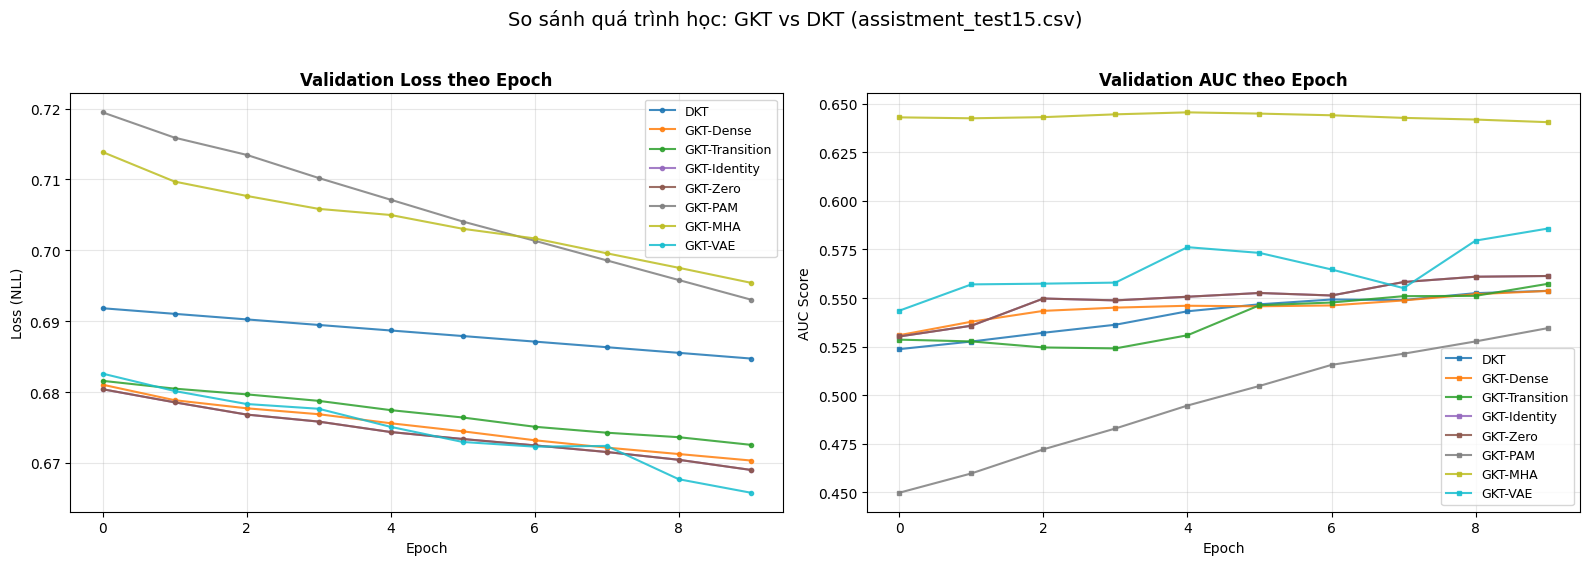

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
colors = plt.cm.tab10(np.linspace(0, 1, len(all_results)))

for i, r in enumerate(all_results):
    label = r['model'] if r['graph_type'] == 'N/A' else f"GKT-{r['graph_type']}"
    h = r['history']
    axes[0].plot(h['val_loss'], label=label, color=colors[i], marker='o', markersize=3, alpha=0.85)
    axes[1].plot(h['val_auc'], label=label, color=colors[i], marker='s', markersize=3, alpha=0.85)

axes[0].set_title('Validation Loss theo Epoch', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (NLL)')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Validation AUC theo Epoch', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC Score')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"So sánh quá trình học: GKT vs DKT ({DATA_FILE})", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gkt_learning_curves.png', dpi=150)
plt.show()


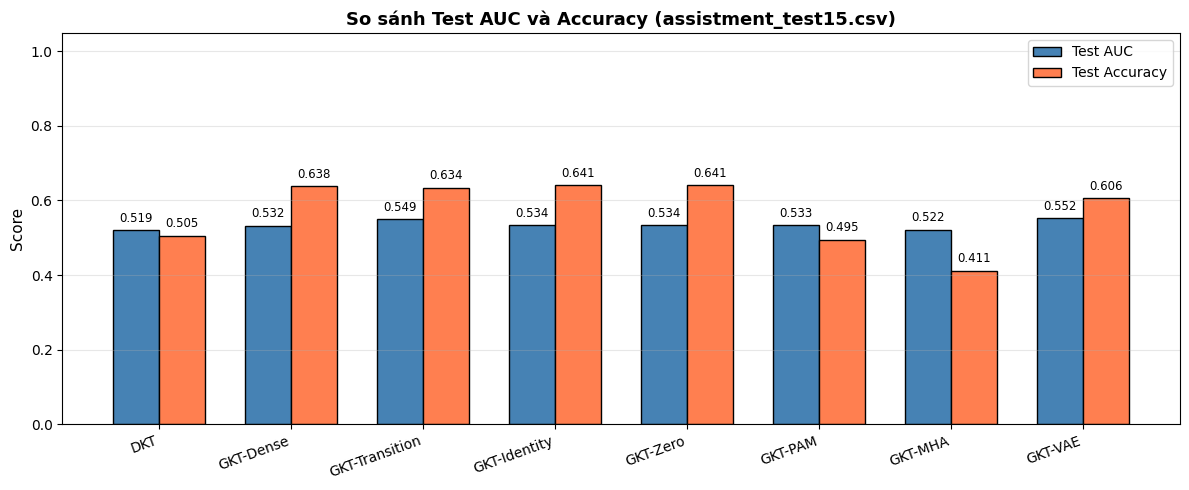

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
model_names = [r['model'] if r['graph_type'] == 'N/A' else f"GKT-{r['graph_type']}" for r in all_results]
aucs = [r['test_auc'] for r in all_results]
accs = [r['test_acc'] for r in all_results]
x = np.arange(len(model_names))
width = 0.35

bars1 = ax.bar(x - width/2, aucs, width, label='Test AUC', color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, accs, width, label='Test Accuracy', color='coral', edgecolor='black')
ax.set_ylabel('Score', fontsize=11)
ax.set_title(f'So sánh Test AUC và Accuracy ({DATA_FILE})', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=20, ha='right', fontsize=10)
ax.legend(fontsize=10)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.015, f"{h:.3f}", ha='center', va='bottom', fontsize=8.5)
for bar in bars2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 0.015, f"{h:.3f}", ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gkt_test_comparison_bars.png', dpi=150)
plt.show()


## 8. Đánh giá đa seed (Multi-seed evaluation: Mean $\pm$ Std)

Chạy 3 seed ngẫu nhiên (`[42, 123, 456]`) với phân chia dữ liệu và khởi tạo độc lập để báo cáo `mean ± std` theo đúng chuẩn nghiên cứu khoa học.


In [13]:
seeds = [42, 123, 456]
multi_seed_configs = [
    {'model_type': 'DKT', 'graph_type': 'N/A'},
    {'model_type': 'GKT', 'graph_type': 'Dense'},
    {'model_type': 'GKT', 'graph_type': 'Transition'},
    {'model_type': 'GKT', 'graph_type': 'Identity'},
]

multi_seed_summary = []

for cfg in multi_seed_configs:
    name = cfg['model_type'] if cfg['graph_type'] == 'N/A' else f"GKT-{cfg['graph_type']}"
    aucs, accs, losses = [], [], []
    for s in seeds:
        print(f"--- {name} | seed={s} ---")
        r = run_experiment(
            data_file=DATA_FILE,
            model_type=cfg['model_type'],
            graph_type=cfg.get('graph_type', 'Dense'),
            epochs=max(5, EPOCHS // 2) if QUICK_RUN else 15,
            batch_size=BATCH_SIZE,
            lr=LR,
            hid_dim=HID_DIM,
            emb_dim=EMB_DIM,
            seed=s
        )
        aucs.append(r['test_auc'])
        accs.append(r['test_acc'])
        losses.append(r['test_loss'])
        
    multi_seed_summary.append({
        'Model': name,
        'AUC Mean': np.mean(aucs),
        'AUC Std': np.std(aucs),
        'Acc Mean': np.mean(accs),
        'Acc Std': np.std(accs),
        'Loss Mean': np.mean(losses),
        'Loss Std': np.std(losses),
    })

print('\n' + '=' * 70)
print('KẾT QUẢ ĐA SEED (3 SEEDS: 42, 123, 456)')
print('=' * 70)
for item in multi_seed_summary:
    print(f"{item['Model']:20s} | AUC: {item['AUC Mean']:.4f} ± {item['AUC Std']:.4f} | Acc: {item['Acc Mean']:.4f} ± {item['Acc Std']:.4f}")

df_multiseed = pd.DataFrame(multi_seed_summary)
multiseed_path = OUTPUT_DIR / 'gkt_multiseed_summary.csv'
df_multiseed.to_csv(multiseed_path, index=False)
print(f"\nĐã lưu kết quả đa seed: {multiseed_path}")


--- DKT | seed=42 ---
max seq_len:  200
student num:  15
feature_dim:  148
question_dim:  74
train_size:  9 val_size:  3 test_size:  3
  Epoch  1/5 | Train Loss=0.6981 AUC=0.4912 Acc=0.4550 | Val Loss=0.6918 AUC=0.5237 Acc=0.5159
  Epoch  2/5 | Train Loss=0.6963 AUC=0.4997 Acc=0.4565 | Val Loss=0.6910 AUC=0.5276 Acc=0.5124
  Epoch  3/5 | Train Loss=0.6945 AUC=0.5075 Acc=0.4689 | Val Loss=0.6903 AUC=0.5321 Acc=0.5406
  Epoch  4/5 | Train Loss=0.6928 AUC=0.5133 Acc=0.4814 | Val Loss=0.6895 AUC=0.5362 Acc=0.5477
  Epoch  5/5 | Train Loss=0.6911 AUC=0.5188 Acc=0.5357 | Val Loss=0.6887 AUC=0.5432 Acc=0.5901
>>> Test: Loss=0.6944 | AUC=0.5118 | Acc=0.5052

--- DKT | seed=123 ---
max seq_len:  200
student num:  15
feature_dim:  148
question_dim:  74
train_size:  9 val_size:  3 test_size:  3
  Epoch  1/5 | Train Loss=0.7015 AUC=0.4381 Acc=0.4549 | Val Loss=0.6874 AUC=0.4883 Acc=0.5865
  Epoch  2/5 | Train Loss=0.6999 AUC=0.4445 Acc=0.4693 | Val Loss=0.6860 AUC=0.5100 Acc=0.5865
  Epoch  3/5 | 

## 9. Tổng kết & Xuất kết quả (Artifacts)


In [14]:
print("=== Danh sách các file kết quả đã tạo ===")
for p in sorted(OUTPUT_DIR.glob('*')):
    print(f" - {p.name} ({p.stat().st_size:,} bytes)")

# Hiển thị bảng tóm tắt cuối cùng
df_summary


=== Danh sách các file kết quả đã tạo ===
 - eda_sequence_distribution.png (71,818 bytes)
 - gkt_benchmark_summary.csv (335 bytes)
 - gkt_learning_curves.png (211,787 bytes)
 - gkt_multiseed_summary.csv (570 bytes)
 - gkt_test_comparison_bars.png (76,672 bytes)


,Model,Graph Type,Test Loss,Test AUC,Test Acc
0,DKT,N/A,0.6912,0.5195,0.5052
1,GKT-Dense,Dense,0.6656,0.5324,0.6376
2,GKT-Transition,Transition,0.6609,0.5495,0.6341
3,GKT-Identity,Identity,0.6638,0.5336,0.6411
4,GKT-Zero,Zero,0.6638,0.5336,0.6411
5,GKT-PAM,PAM,0.6960,0.5335,0.4948
6,GKT-MHA,MHA,0.7167,0.5216,0.4111
7,GKT-VAE,VAE,0.6735,0.5522,0.6063
